**Data sources for comment reference:**
1. Kowal et al. (2025) *Cross-cultural data on romantic love and mate
   preferences from 117,293 participants across 175 countries*
   `Final_dataset.csv` (download from OSF: https://doi.org/10.17605/osf.io/K54FX)
2. Berkeley Earth (via Kaggle) `GlobalLandTemperaturesByCountry.csv`,
   monthly average land temperature by country (1743-2013). 

## 1. Setup & Imports

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import country_converter as coco

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

_cc = coco.CountryConverter()

def map_to_iso3(names):
    sentinel = "___NOT_FOUND___"
    results = _cc.convert(names=list(names), to="ISO3", not_found=sentinel)
    return [None if r == sentinel else r for r in results]


In [38]:
CODEBOOK_PATH = "./codebook/Codebook.xlsx"          # Codebook provided with dataset 1
SURVEY_DATA_PATH = "./dataset/Final_dataset.csv"    # Dataset 1: Cross-cultural data on romantic love
CLIMATE_DATA_PATH = "./dataset/GlobalLandTemperaturesByCountry.csv"  # Dataset 2: Berkeley Earth

MIN_PARTICIPANTS_PER_COUNTRY = 30  
COMFORT_TEMP_C = 22.0              

CLIMATOLOGY_START_YEAR = 1991
CLIMATOLOGY_END_YEAR = 2012

## 2. Loading the Codebook for Inspection

In [39]:
codebook = pd.read_excel(CODEBOOK_PATH)
codebook.head(20)

,CATEGORY,SUBCATEGORY,VARIABLES,VARIABLE NAME,ITEMS,RESPONSE OPTIONS,SCALE
0,SELF,Demographics,Language,UserLanguage,Default version in native language,List with available translations: English (EN)...,NaN
1,SELF,Demographics,Age,Age,How old are you (in years)?,18 to 90 (one-year intervals),NaN
2,SELF,Demographics,Gender,Sex,What is your gender?,Male (0); Female (1); Non-binary (2); Prefer n...,NaN
3,SELF,Demographics,Gender (Computed score),Sex_recoded,A transformed Sex variable with labels instead...,"""Men"", ""Non-binary"", ""Prefer not to say"", ""Women""",NaN
4,SELF,Demographics,Gender (Computed score),Sex01,A dichotomized Sex variable,"Men (0), Women (1), other sexes denoted as mis...",NaN
5,SELF,Demographics,Gender (Computed score),Sex01_recoded,"A dichotomized Sex variable, with recoded labels","""Men"", ""Women"", other sexes denoted as missing",NaN
6,SELF,Demographics,Sex at birth,Sex_birth,What was your sex at birth?,Male (0); Female (1); Intersex (2),NaN
7,SELF,Demographics,Sexual orientation,Sexual_Orientation,Please select the sexual orientation label(s) ...,Heterosexual or straight (1); Gay (2); Lesbian...,NaN
8,SELF,Demographics,Sexual orientation,Sexual_Orientation_8_TEXT,NaN,TEXT input from Participants,NaN
9,SELF,Demographics,Sexual orientation (Computed score),Sexual_Orientation_recoded,A transformed Sexual_Orientation variable with...,Heterosexual or straight; Gay; Lesbian; Bisexu...,NaN


In [40]:
needed_vars = [
    "Country_raised", "Love_currently", "Intimacy", "Passion",
    "Commitment", "Relationship_length",
]
codebook[codebook["VARIABLE NAME"].isin(needed_vars)][
    ["CATEGORY", "SUBCATEGORY", "VARIABLES", "VARIABLE NAME"]
]


,CATEGORY,SUBCATEGORY,VARIABLES,VARIABLE NAME
15,SELF,Demographics,Country of birth,Country_raised
114,PAIR,Love,Love feelings at present,Love_currently
116,PAIR,Love,Love (Computed score),Intimacy
117,PAIR,Love,Love (Computed score),Passion
118,PAIR,Love,Love (Computed score),Commitment
141,PAIR,Relationships,Relationship duration1,Relationship_length


## 3. Load Survey Data and Filter to Relevant Respondents

We keep participants who currently report love feelings (since `Intimacy`,
`Passion`, and `Commitment` are only computed for this group) and who have
non-missing scores on the three love components.

In [41]:
df = pd.read_csv(SURVEY_DATA_PATH, sep=";", encoding="utf-8", encoding_errors="replace")

cols_needed = [
    "Country_raised", "Love_currently", "Intimacy", "Passion",
    "Commitment", "Relationship_length",
]
df = df[cols_needed].copy()

# Keep only those currently reporting love feelings with complete love scores
df = df[df["Love_currently"] == 1]  # 1 means "Yes" according to the codebook
df = df.dropna(subset=["Intimacy", "Passion", "Commitment"])

print(df.shape)
df.head()

(46408, 6)


C:\Users\Hamidur\AppData\Local\Temp\ipykernel_15564\2340190051.py:1: DtypeWarning: Columns (21: Sexual_Orientation_8_TEXT, 22: Employment, 68: Attract_which_other_TEXT, 109: cp_educ, 110: cp_politics, 111: cp_class, 271: cpt_educ_recoded, 272: cpt_politics_recoded, 273: cpt_class_recoded) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(SURVEY_DATA_PATH, sep=";", encoding="utf-8", encoding_errors="replace")


,Country_raised,Love_currently,Intimacy,Passion,Commitment,Relationship_length
3,Nigeria,1.0,3.4,3.4,3.8,3.0
6,Nigeria,1.0,3.2,3.0,3.0,1.0
10,Nigeria,1.0,3.4,3.0,3.0,3.0
11,Nigeria,1.0,2.6,2.6,3.2,6.0
12,Nigeria,1.0,5.0,5.0,5.0,4.0


**Note:** Warning can be ignored because the mentioned columns are not required for analysis.

## 4. Aggregate to Country Level

One row per country: mean love scores, mean relationship length, and
participant count. Countries below `MIN_PARTICIPANTS_PER_COUNTRY` are dropped.

In [42]:
country_agg = (
    df.groupby("Country_raised")
    .agg(
        Intimacy=("Intimacy", "mean"),
        Passion=("Passion", "mean"),
        Commitment=("Commitment", "mean"),
        Relationship_length=("Relationship_length", "mean"),
        n_participants=("Intimacy", "size"),
    )
    .reset_index()
)

country_agg = country_agg[country_agg["n_participants"] >= MIN_PARTICIPANTS_PER_COUNTRY]
print(f"Countries retained: {len(country_agg)}")
country_agg.sort_values("n_participants", ascending=False).head(10)


Countries retained: 81


,Country_raised,Intimacy,Passion,Commitment,Relationship_length,n_participants
150,Turkey,4.339027,3.981779,4.337224,4.569832,3817
118,Poland,4.500791,4.078151,4.490527,5.308930,3795
72,Italy,4.349391,3.940464,4.417539,8.319527,2903
154,USA,4.484610,4.067275,4.514402,10.326058,2245
99,Morocco,3.657410,3.536391,3.551736,6.773731,1815
122,Russia,4.360175,4.005339,4.533944,5.417676,1692
33,Chile,4.393190,3.793874,4.341965,5.384973,1510
53,France,4.226613,3.704030,4.170648,5.522091,1369
156,Ukraine,4.410487,4.050167,4.483486,4.977570,1095
38,Croatia,4.572934,4.258922,4.560949,5.521614,1061


## 5. Standardize Country Identifiers (ISO3)

In [43]:
country_agg["iso3"] = map_to_iso3(country_agg["Country_raised"])

still_missing = country_agg[country_agg["iso3"].isna()]
print(f"Unmatched ({len(still_missing)}):")
still_missing[["Country_raised", "n_participants"]]


Unmatched (0):


,Country_raised,n_participants


## 6. Source Monthly Temperature Data 

In [44]:
climate_raw = pd.read_csv(CLIMATE_DATA_PATH, parse_dates=["dt"])
climate_raw["year"] = climate_raw["dt"].dt.year
climate_raw["month"] = climate_raw["dt"].dt.month

print(f"Date range: {climate_raw['dt'].min()} to {climate_raw['dt'].max()}")
print(f"Countries in raw file: {climate_raw['Country'].nunique()}")

climate_normal = climate_raw[
    (climate_raw["year"] >= CLIMATOLOGY_START_YEAR)
    & (climate_raw["year"] <= CLIMATOLOGY_END_YEAR)
].dropna(subset=["AverageTemperature"])

Date range: 1743-11-01 00:00:00 to 2013-09-01 00:00:00
Countries in raw file: 243


In [45]:
# average temperature per country per calendar month, across all years in the normal period
climate_monthly = (
    climate_normal.groupby(["Country", "month"])["AverageTemperature"]
    .mean()
    .reset_index()
    .rename(columns={"AverageTemperature": "avg_temp_c"})
)

climate_monthly.head(15)


,Country,month,avg_temp_c
0,Afghanistan,1,1.487182
1,Afghanistan,2,3.977864
2,Afghanistan,3,9.636136
3,Afghanistan,4,15.662864
4,Afghanistan,5,21.301091
5,Afghanistan,6,25.844045
6,Afghanistan,7,27.713182
7,Afghanistan,8,26.242091
8,Afghanistan,9,21.391500
9,Afghanistan,10,15.098455


## 7. Compute Cold Demands and Heat Demands

Per Van de Vliert's climato-economic index (simplified):

- **Cold demands** = downward deviation from 22°C in the coldest month
- **Heat demands** = upward deviation from 22°C in the hottest month

In [46]:
def compute_thermal_demands(monthly_df: pd.DataFrame, comfort_temp: float = COMFORT_TEMP_C) -> pd.DataFrame:
    records = []
    for country, group in monthly_df.groupby("Country"):
        coldest_temp = group["avg_temp_c"].min()
        hottest_temp = group["avg_temp_c"].max()

        cold_demand = max(0.0, comfort_temp - coldest_temp)
        heat_demand = max(0.0, hottest_temp - comfort_temp)

        records.append({
            "Country": country,
            "coldest_month_temp": coldest_temp,
            "hottest_month_temp": hottest_temp,
            "cold_demands": cold_demand,
            "heat_demands": heat_demand,
        })
    return pd.DataFrame(records)

climate_features = compute_thermal_demands(climate_monthly)

print(f"Countries with computed climate features: {len(climate_features)}")
print(f"Correlation between cold_demands and heat_demands: "
      f"{climate_features['cold_demands'].corr(climate_features['heat_demands']):.3f}")
climate_features.sort_values('cold_demands', ascending=False).head(10)


Countries with computed climate features: 242
Correlation between cold_demands and heat_demands: -0.653


,Country,coldest_month_temp,hottest_month_temp,cold_demands,heat_demands
87,Greenland,-29.574682,-1.011591,51.574682,0.000000
57,Denmark,-28.951227,-0.634364,50.951227,0.000000
179,Russia,-23.980364,15.927136,45.980364,0.000000
38,Canada,-21.723909,13.598727,43.723909,0.000000
143,Mongolia,-21.014273,19.070818,43.014273,0.000000
209,Svalbard And Jan Mayen,-14.313545,4.534955,36.313545,0.000000
114,Kazakhstan,-12.109364,23.564727,34.109364,1.564727
119,Kyrgyzstan,-11.147364,17.132500,33.147364,0.000000
158,North America,-10.514773,16.953091,32.514773,0.000000
74,Finland,-9.952773,16.110682,31.952773,0.000000


### 7a. Map Climate Data Country Names to ISO3

In [47]:
climate_features["iso3"] = map_to_iso3(climate_features["Country"])

still_missing = climate_features[climate_features["iso3"].isna()]
print(f"Unmatched ({len(still_missing)})")
print(still_missing["Country"].tolist())

climate_features = climate_features.dropna(subset=["iso3"])
print(f"\nMatched climate feature rows: {len(climate_features)}")


Africa not found in regex
Asia not found in regex
Baker Island not found in regex
Europe not found in regex
Kingman Reef not found in regex
North America not found in regex
Oceania not found in regex
Palmyra Atoll not found in regex
South America not found in regex
Virgin Islands not found in regex


Unmatched (10)
['Africa', 'Asia', 'Baker Island', 'Europe', 'Kingman Reef', 'North America', 'Oceania', 'Palmyra Atoll', 'South America', 'Virgin Islands']

Matched climate feature rows: 232


**Note:** 
- a couple of raw country names can map to the *same* ISO3
code (e.g. "Palestina" and "Gaza Strip" both resolve to PSE). Left as-is,
this would create duplicate rows for one country when merging. We collapse
these by averaging before moving on.
- continents are not required for analysis, thus ignored

In [48]:
dup_iso3 = climate_features["iso3"].duplicated(keep=False)
if dup_iso3.any():
    print("Duplicate iso3 codes found:")
    print(climate_features[dup_iso3][["Country", "iso3"]])

    climate_features = (
        climate_features.groupby("iso3", as_index=False)
        .agg({
            "coldest_month_temp": "mean",
            "hottest_month_temp": "mean",
            "cold_demands": "mean",
            "heat_demands": "mean",
        })
    )

print(f"\nFinal climate feature table length: {len(climate_features)}")


Duplicate iso3 codes found:
                     Country iso3
57                   Denmark  DNK
58          Denmark (Europe)  DNK
75                    France  FRA
76           France (Europe)  FRA
82                Gaza Strip  PSE
150              Netherlands  NLD
151     Netherlands (Europe)  NLD
166                Palestina  PSE
229           United Kingdom  GBR
230  United Kingdom (Europe)  GBR

Final climate feature table length: 227


## 8. Merge Climate Features onto the Country-Level Survey Table

In [49]:
analysis_df = country_agg.merge(climate_features, on="iso3", how="inner")
print(f"Countries with both survey and climate data: {len(analysis_df)}")
analysis_df.head()


Countries with both survey and climate data: 80


,Country_raised,Intimacy,Passion,Commitment,Relationship_length,n_participants,iso3,coldest_month_temp,hottest_month_temp,cold_demands,heat_demands
0,Albania,4.010753,3.802151,4.111290,7.645161,31,ALB,3.855545,23.453318,18.144455,1.453318
1,Algeria,3.893711,3.763132,3.980682,4.891791,811,DZA,12.437818,34.787273,9.562182,12.787273
2,Angola,4.409016,4.099454,4.395902,9.327869,61,AGO,19.431955,24.272409,2.568045,2.272409
3,Argentina,4.266585,3.709877,4.351137,17.971652,1026,ARG,7.905136,21.897682,14.094864,0.000000
4,Australia,4.533990,3.946552,4.533251,7.305000,203,AUS,14.907364,28.436864,7.092636,6.436864


In [50]:
survey_isos = set(country_agg["iso3"])
climate_isos = set(climate_features["iso3"])
print(survey_isos - climate_isos)

{'BRN'}


## 9. Finalize data for modeling

- Drop rows with any remaining missing values
- Check for outliers
- Save the final tidy modeling table

In [51]:
analysis_df = analysis_df.dropna(
    subset=["Intimacy", "Passion", "Commitment", "Relationship_length",
            "cold_demands", "heat_demands"]
)

print(analysis_df[["Intimacy", "Passion", "Commitment", "Relationship_length",
                    "cold_demands", "heat_demands"]].describe())

analysis_df.to_csv("country_level_analysis_table.csv", index=False)
analysis_df.head()


        Intimacy    Passion  Commitment  Relationship_length  cold_demands  heat_demands
count  80.000000  80.000000   80.000000            80.000000     80.000000     80.000000
mean    4.368232   3.975992    4.360486             6.876731     15.183289      2.830070
std     0.187856   0.205670    0.215632             2.792799     11.138815      3.456530
min     3.539777   3.504958    3.551736             2.790476      0.000000      0.000000
25%     4.317936   3.875250    4.287124             5.279614      5.101409      0.000000
50%     4.388917   3.994033    4.378297             6.182403     16.144068      1.295295
75%     4.467665   4.080672    4.516105             7.599562     23.037034      5.220659
max     4.786024   4.801302    4.833247            17.971652     45.980364     15.387273


,Country_raised,Intimacy,Passion,Commitment,Relationship_length,n_participants,iso3,coldest_month_temp,hottest_month_temp,cold_demands,heat_demands
0,Albania,4.010753,3.802151,4.111290,7.645161,31,ALB,3.855545,23.453318,18.144455,1.453318
1,Algeria,3.893711,3.763132,3.980682,4.891791,811,DZA,12.437818,34.787273,9.562182,12.787273
2,Angola,4.409016,4.099454,4.395902,9.327869,61,AGO,19.431955,24.272409,2.568045,2.272409
3,Argentina,4.266585,3.709877,4.351137,17.971652,1026,ARG,7.905136,21.897682,14.094864,0.000000
4,Australia,4.533990,3.946552,4.533251,7.305000,203,AUS,14.907364,28.436864,7.092636,6.436864


## 10. Data Quality & Visual Inspection

- Scatterplots of each climate feature vs. each love component
- Correlation between `cold_demands` and `heat_demands` 
- Correlation between `Relationship_length` and `Intimacy` 

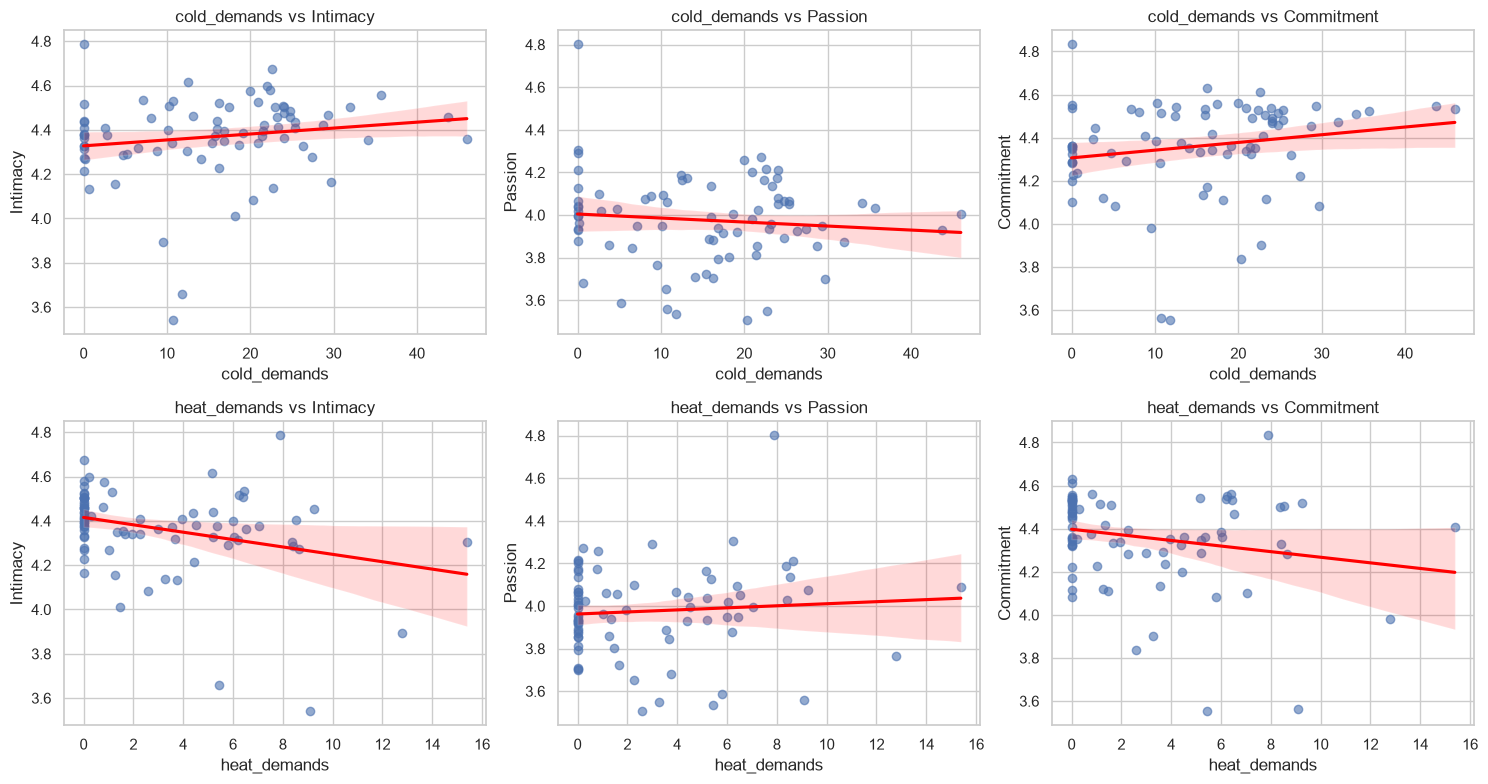

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
targets = ["Intimacy", "Passion", "Commitment"]
features = ["cold_demands", "heat_demands"]

for i, feat in enumerate(features):
    for j, target in enumerate(targets):
        ax = axes[i, j]
        sns.regplot(data=analysis_df, x=feat, y=target, ax=ax,
                    scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
        ax.set_title(f"{feat} vs {target}")

plt.tight_layout()
plt.show()


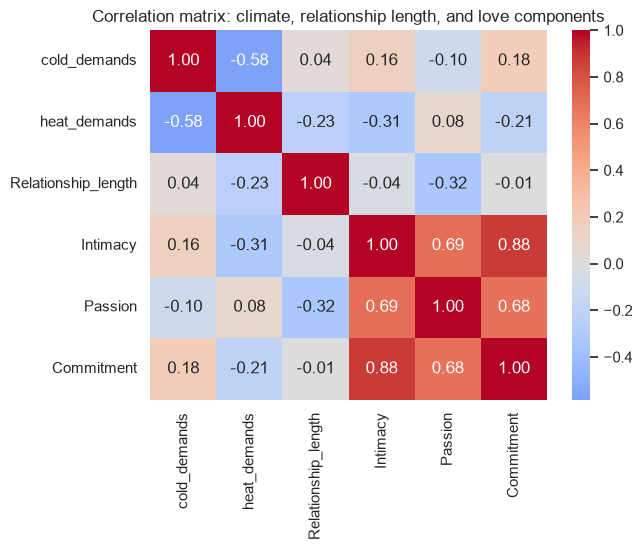

Final country count: 80


In [53]:
corr_check = analysis_df[["cold_demands", "heat_demands", "Relationship_length",
                           "Intimacy", "Passion", "Commitment"]].corr()
sns.heatmap(corr_check, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix: climate, relationship length, and love components")
plt.show()

print(f"Final country count: {len(analysis_df)}")


## 11. Modeling: Linear Regression

Fit model across:
- **3 targets:** Intimacy, Passion, Commitment
- **2 feature sets:**
  - Model A (climate only): `cold_demands`, `heat_demands`
  - Model B (climate + control): `cold_demands`, `heat_demands`, `Relationship_length`

Evaluation uses k-fold cross-validation.

In [54]:
feature_sets = {
    "climate_only": ["cold_demands", "heat_demands"],
    "climate_plus_rel_length": ["cold_demands", "heat_demands", "Relationship_length"],
}

models = {
    "Linear Regression": LinearRegression(),
}

targets = ["Intimacy", "Passion", "Commitment"]

results = []
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for target in targets:
    y = analysis_df[target]
    for fs_name, fs_cols in feature_sets.items():
        X = analysis_df[fs_cols]
        for model_name, model in models.items():
            r2_scores = cross_val_score(model, X, y, cv=kf, scoring="r2")
            results.append({
                "target": target,
                "feature_set": fs_name,
                "model": model_name,
                "mean_r2": r2_scores.mean(),
                "std_r2": r2_scores.std(),
            })

results_df = pd.DataFrame(results).sort_values(["target", "feature_set", "model"])
results_df


,target,feature_set,model,mean_r2,std_r2
4,Commitment,climate_only,Linear Regression,-0.188083,0.312264
5,Commitment,climate_plus_rel_length,Linear Regression,-0.240350,0.333894
0,Intimacy,climate_only,Linear Regression,-0.086733,0.184631
1,Intimacy,climate_plus_rel_length,Linear Regression,-0.084061,0.229824
2,Passion,climate_only,Linear Regression,-0.205186,0.147021
3,Passion,climate_plus_rel_length,Linear Regression,-0.023439,0.160822
